# EDA: dane irysów

Jerzy Śliwa · praca domowa z kursu „Od zera do AI” (moduł 4)

## O Danych

Zbiór danych zawiera informacje o trzech gatunkach irysów: Iris setosa, Iris versicolor, i Iris virginica.

Dane obejmują pomiary czterech cech: długość i szerokość działki kielicha oraz długość i szerokość płatka.

Każdy wiersz w zbiorze danych reprezentuje pojedynczy kwiat, a wartości pomiarów są podane w centymetrach.

Zbiór składa się z 150 próbek, po 50 dla każdego gatunku.

Kolumny:
* **długość kielicha (sepal length)** - Długość kielicha w cm
* **szerokość kielicha (sepal width)** - Szerokość kielicha w cm
* **długość płatka (petal length)** - Długość płatka w cm
* **szerokość płatka (petal width)** - Szerokość płatka w cm
* **klasa (class)** - Klasa irysa (setosa, versicolor, virginica)

## Plan analizy
1. Ogólny przegląd danych
2. Brakujące wartości i duplikaty
3. Przygotowanie danych
4. Analiza pojedynczych zmiennych
5. Porównanie gatunków
6. Relacje między kolumnami
7. Wartości odstające
8. Podsumowanie i wnioski

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('25__iris.csv', sep=",")
df

,długość kielicha (sepal length),szerokość kielicha (sepal width),długość płatka (petal length),szerokość płatka (petal width),klasa (class)
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


## 1. Ogólny przegląd danych

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   długość kielicha (sepal length)   150 non-null    float64
 1   szerokość kielicha (sepal width)  150 non-null    float64
 2   długość płatka (petal length)     150 non-null    float64
 3   szerokość płatka (petal width)    150 non-null    float64
 4   klasa (class)                     150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


**Obserwacje:**
* Zbiór ma 150 wierszy (indeks od 0 do 149) i 5 kolumn.
* 4 kolumny to liczby zmiennoprzecinkowe (`float64`) – pomiary w cm.
* 1 kolumna jest tekstowa – nazwa gatunku.
* W każdej kolumnie jest 150 wartości niepustych, więc najprawdopodobniej nie ma braków. Sprawdzę to jeszcze w punkcie 2.
* Typy danych są poprawne, nie trzeba niczego konwertować.

In [4]:
df.head()

,długość kielicha (sepal length),szerokość kielicha (sepal width),długość płatka (petal length),szerokość płatka (petal width),klasa (class)
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [5]:
df.tail()

,długość kielicha (sepal length),szerokość kielicha (sepal width),długość płatka (petal length),szerokość płatka (petal width),klasa (class)
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica
149,5.9,3.0,5.1,1.8,Iris-virginica


**Obserwacja:** na początku tabeli są same *setosa*, a na końcu same *virginica*. Wygląda na to, że dane są posortowane według gatunku.

In [6]:
df.sample(10)

,długość kielicha (sepal length),szerokość kielicha (sepal width),długość płatka (petal length),szerokość płatka (petal width),klasa (class)
128,6.4,2.8,5.6,2.1,Iris-virginica
142,5.8,2.7,5.1,1.9,Iris-virginica
39,5.1,3.4,1.5,0.2,Iris-setosa
34,4.9,3.1,1.5,0.1,Iris-setosa
67,5.8,2.7,4.1,1.0,Iris-versicolor
59,5.2,2.7,3.9,1.4,Iris-versicolor
108,6.7,2.5,5.8,1.8,Iris-virginica
114,5.8,2.8,5.1,2.4,Iris-virginica
144,6.7,3.3,5.7,2.5,Iris-virginica
13,4.3,3.0,1.1,0.1,Iris-setosa


**Obserwacja:** dopiero losowa próbka pokazuje wszystkie trzy gatunki, w tym *versicolor*, który jest w środku tabeli.

In [7]:
df.nunique()

długość kielicha (sepal length)     35
szerokość kielicha (sepal width)    23
długość płatka (petal length)       43
szerokość płatka (petal width)      22
klasa (class)                        3
dtype: int64

In [8]:
df['klasa (class)'].value_counts()

klasa (class)
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

**Obserwacje:**
* Są 3 gatunki i każdy ma dokładnie 50 próbek – zbiór jest równo podzielony. Dzięki temu porównania między gatunkami będą uczciwe.
* Kolumny z pomiarami mają od 22 do 43 unikalnych wartości. To niewiele, bo pomiary są zapisane z dokładnością do 0,1 cm. Będzie to ważne przy duplikatach.

## 2. Brakujące wartości i duplikaty

### 2.1 Brakujące wartości

In [9]:
df.isnull().sum()

długość kielicha (sepal length)     0
szerokość kielicha (sepal width)    0
długość płatka (petal length)       0
szerokość płatka (petal width)      0
klasa (class)                       0
dtype: int64

**Wniosek:** w żadnej kolumnie nie ma braków. Nie trzeba niczego uzupełniać.

### 2.2 Duplikaty

In [10]:
df.duplicated().sum()

3

In [11]:
df[df.duplicated()]

,długość kielicha (sepal length),szerokość kielicha (sepal width),długość płatka (petal length),szerokość płatka (petal width),klasa (class)
34,4.9,3.1,1.5,0.1,Iris-setosa
37,4.9,3.1,1.5,0.1,Iris-setosa
142,5.8,2.7,5.1,1.9,Iris-virginica


**Obserwacja:** są 3 zduplikowane wiersze: 34, 37 i 142. Sprawdzam, z którymi wierszami się powtarzają.

In [12]:
df[(df['długość kielicha (sepal length)'] == 4.9) &
   (df['szerokość kielicha (sepal width)'] == 3.1) &
   (df['długość płatka (petal length)'] == 1.5)]

,długość kielicha (sepal length),szerokość kielicha (sepal width),długość płatka (petal length),szerokość płatka (petal width),klasa (class)
9,4.9,3.1,1.5,0.1,Iris-setosa
34,4.9,3.1,1.5,0.1,Iris-setosa
37,4.9,3.1,1.5,0.1,Iris-setosa


In [13]:
df[(df['długość kielicha (sepal length)'] == 5.8) &
   (df['szerokość kielicha (sepal width)'] == 2.7) &
   (df['długość płatka (petal length)'] == 5.1)]

,długość kielicha (sepal length),szerokość kielicha (sepal width),długość płatka (petal length),szerokość płatka (petal width),klasa (class)
101,5.8,2.7,5.1,1.9,Iris-virginica
142,5.8,2.7,5.1,1.9,Iris-virginica


**Obserwacje:**
* wiersze 34 i 37 są takie same jak wiersz 9 (*setosa*),
* wiersz 142 jest taki sam jak wiersz 101 (*virginica*).

**Czy usunąć duplikaty?** Każdy wiersz to osobny kwiat, a pomiary są zaokrąglone do 0,1 cm. Kwiaty jednego gatunku są do siebie bardzo podobne, więc dwa różne kwiaty mogą mieć identyczne wymiary.
Z samych danych nie da się sprawdzić, czy to błąd – nie ma np. numeru próbki ani daty pomiaru.

Sprawdzam więc, czy usunięcie duplikatów zmieniłoby wyniki.

In [14]:
df_bez_duplikatow = df.drop_duplicates()
df_bez_duplikatow['klasa (class)'].value_counts()

klasa (class)
Iris-versicolor    50
Iris-virginica     49
Iris-setosa        48
Name: count, dtype: int64

In [15]:
df.groupby('klasa (class)').mean()

,długość kielicha (sepal length),szerokość kielicha (sepal width),długość płatka (petal length),szerokość płatka (petal width)
klasa (class),,,,
Iris-setosa,5.006,3.418,1.464,0.244
Iris-versicolor,5.936,2.770,4.260,1.326
Iris-virginica,6.588,2.974,5.552,2.026


In [16]:
df_bez_duplikatow.groupby('klasa (class)').mean()

,długość kielicha (sepal length),szerokość kielicha (sepal width),długość płatka (petal length),szerokość płatka (petal width)
klasa (class),,,,
Iris-setosa,5.010417,3.431250,1.462500,0.250000
Iris-versicolor,5.936000,2.770000,4.260000,1.326000
Iris-virginica,6.604082,2.979592,5.561224,2.028571


**Wniosek:**
* Po usunięciu duplikatów średnie zmieniają się o mniej niż 0,02 cm – praktycznie bez znaczenia.
* Zaburzyłoby to za to równy podział gatunków (48 / 50 / 49).

**Decyzja:** zostawiam wszystkie 150 wierszy. Duplikaty odnotowuję jako obserwację.

## 3. Przygotowanie danych

Nazwy kolumn są długie, więc dla wygody zmieniam je na krótsze. Z nazw gatunków usuwam powtarzający się przedrostek `Iris-`.

In [17]:
df = df.rename(columns={
    'długość kielicha (sepal length)': 'dl_kielicha',
    'szerokość kielicha (sepal width)': 'szer_kielicha',
    'długość płatka (petal length)': 'dl_platka',
    'szerokość płatka (petal width)': 'szer_platka',
    'klasa (class)': 'gatunek',
})

df['gatunek'] = df['gatunek'].str.replace('Iris-', '')
df.head()

,dl_kielicha,szer_kielicha,dl_platka,szer_platka,gatunek
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Dodaję też nową kolumnę – przybliżone pole płatka (długość × szerokość). Chcę sprawdzić, czy jedna liczba opisująca wielkość płatka dobrze odróżnia gatunki.

In [18]:
df['pole_platka'] = df['dl_platka'] * df['szer_platka']
df.head()

,dl_kielicha,szer_kielicha,dl_platka,szer_platka,gatunek,pole_platka
0,5.1,3.5,1.4,0.2,setosa,0.28
1,4.9,3.0,1.4,0.2,setosa,0.28
2,4.7,3.2,1.3,0.2,setosa,0.26
3,4.6,3.1,1.5,0.2,setosa,0.30
4,5.0,3.6,1.4,0.2,setosa,0.28


## 4. Analiza pojedynczych zmiennych

In [19]:
df.describe()

,dl_kielicha,szer_kielicha,dl_platka,szer_platka,pole_platka
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667,5.793133
std,0.828066,0.433594,1.764420,0.763161,4.713499
min,4.300000,2.000000,1.000000,0.100000,0.110000
25%,5.100000,2.800000,1.600000,0.300000,0.420000
50%,5.800000,3.000000,4.350000,1.300000,5.615000
75%,6.400000,3.300000,5.100000,1.800000,9.690000
max,7.900000,4.400000,6.900000,2.500000,15.870000


In [20]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
dl_kielicha,150.0,5.843333,0.828066,4.30,5.10,5.800,6.40,7.90
szer_kielicha,150.0,3.054000,0.433594,2.00,2.80,3.000,3.30,4.40
dl_platka,150.0,3.758667,1.764420,1.00,1.60,4.350,5.10,6.90
szer_platka,150.0,1.198667,0.763161,0.10,0.30,1.300,1.80,2.50
pole_platka,150.0,5.793133,4.713499,0.11,0.42,5.615,9.69,15.87


**Obserwacje:**
* **Długość płatka** ma największy rozrzut (odchylenie standardowe 1,76 cm, zakres od 1,0 do 6,9 cm). Średnia (3,76) wyraźnie różni się od mediany (4,35), co sugeruje, że w danych są różne grupy kwiatów.
* **Szerokość kielicha** ma najmniejszy rozrzut (odchylenie 0,43 cm), a średnia i mediana są prawie równe (3,05 i 3,00).
* **Długość kielicha** – średnia i mediana też są blisko siebie (5,84 i 5,80).

array([[<Axes: title={'center': 'dl_kielicha'}>,
        <Axes: title={'center': 'szer_kielicha'}>],
       [<Axes: title={'center': 'dl_platka'}>,
        <Axes: title={'center': 'szer_platka'}>],
       [<Axes: title={'center': 'pole_platka'}>, <Axes: >]], dtype=object)

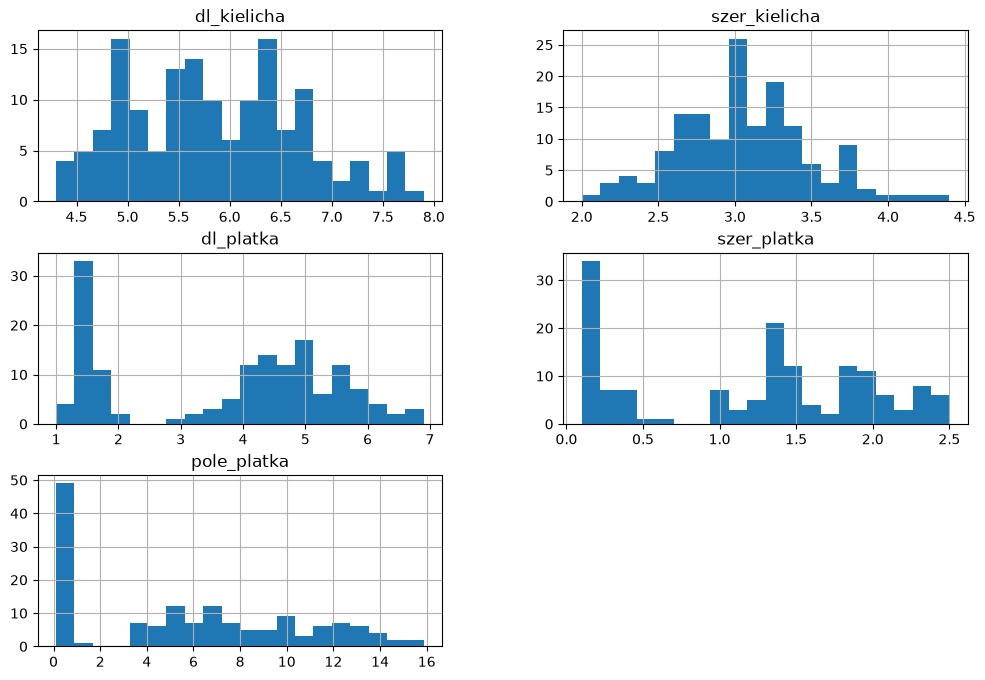

In [21]:
df.hist(figsize=(12, 8), bins=20)

**Obserwacje z histogramów:**
* Histogramy **długości i szerokości płatka** mają dwie wyraźne grupy z przerwą pomiędzy (ok. 2–3 cm dla długości i ok. 0,6–1,0 cm dla szerokości). Lewa grupa to najpewniej jeden gatunek – sprawdzę to w punkcie 5.
* **Szerokość kielicha** ma jeden szczyt w środku i pojedyncze wartości na krańcach.
* **Długość kielicha** ma jeden szczyt, wartości rozkładają się dość równomiernie.
* **Pole płatka** też ma wyraźnie oddzieloną grupę małych wartości.

## 5. Porównanie gatunków

In [22]:
df.groupby('gatunek').mean()

,dl_kielicha,szer_kielicha,dl_platka,szer_platka,pole_platka
gatunek,,,,,
setosa,5.006,3.418,1.464,0.244,0.3628
versicolor,5.936,2.770,4.260,1.326,5.7204
virginica,6.588,2.974,5.552,2.026,11.2962


In [23]:
df.groupby('gatunek', as_index=False).agg({
    'dl_platka': ['min', 'max', 'mean', 'median'],
    'szer_platka': ['min', 'max', 'mean', 'median'],
})

gatunek dl_platka                    szer_platka                   
                    min  max   mean median         min  max   mean median
0      setosa       1.0  1.9  1.464   1.50         0.1  0.6  0.244    0.2
1  versicolor       3.0  5.1  4.260   4.35         1.0  1.8  1.326    1.3
2   virginica       4.5  6.9  5.552   5.55         1.4  2.5  2.026    2.0

In [24]:
df.groupby('gatunek', as_index=False).agg({
    'dl_kielicha': ['min', 'max', 'mean', 'median'],
    'szer_kielicha': ['min', 'max', 'mean', 'median'],
})

gatunek dl_kielicha                    szer_kielicha                   
                      min  max   mean median           min  max   mean median
0      setosa         4.3  5.8  5.006    5.0           2.3  4.4  3.418    3.4
1  versicolor         4.9  7.0  5.936    5.9           2.0  3.4  2.770    2.8
2   virginica         4.9  7.9  6.588    6.5           2.2  3.8  2.974    3.0

**Obserwacje:**
* *Setosa* ma zdecydowanie najmniejsze płatki: długość od 1,0 do 1,9 cm i szerokość od 0,1 do 0,6 cm. Pozostałe gatunki zaczynają się od 3,0 cm długości i 1,0 cm szerokości, więc *setosa* w ogóle się z nimi nie miesza.
* *Virginica* jest największa we wszystkich wymiarach oprócz szerokości kielicha.
* **Szerokość kielicha** zachowuje się inaczej niż reszta – to *setosa* ma najszerszy kielich (średnio 3,42 cm), mimo że pod każdym innym względem jest najmniejsza.
* *Versicolor* i *virginica* częściowo się nakładają, np. długość płatka: *versicolor* do 5,1 cm, a *virginica* od 4,5 cm.

<Axes: title={'center': 'Średnie wymiary według gatunku'}, xlabel='gatunek'>

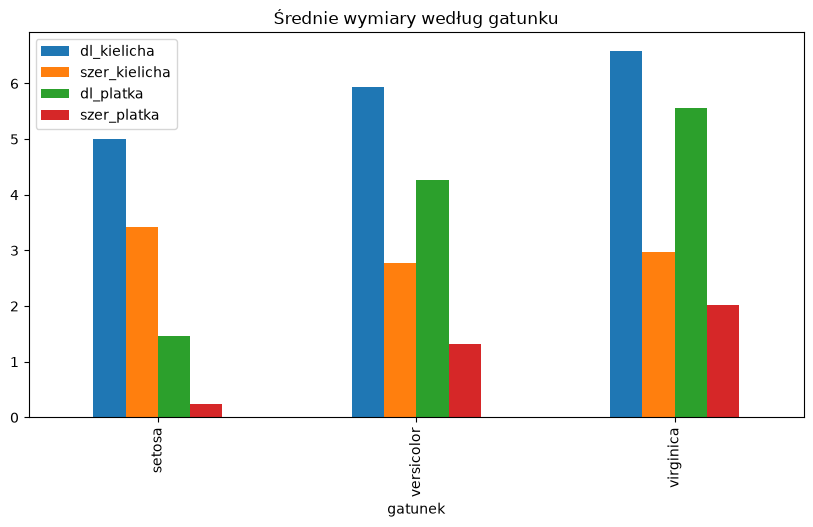

In [25]:
df.groupby('gatunek')[['dl_kielicha', 'szer_kielicha', 'dl_platka', 'szer_platka']].mean().plot(kind='bar', figsize=(10, 5), title='Średnie wymiary według gatunku')

**Obserwacja:** na wykresie najlepiej widać różnicę w długości płatka – słupki rosną wyraźnie od *setosa* do *virginica*. Przy szerokości kielicha słupki są prawie równe.

In [26]:
df.groupby('gatunek', as_index=False).agg({'pole_platka': ['min', 'max', 'mean']})

gatunek pole_platka                
                      min    max     mean
0      setosa        0.11   0.96   0.3628
1  versicolor        3.30   8.64   5.7204
2   virginica        7.50  15.87  11.2962

**Obserwacja:** pole płatka *setosa* nie przekracza 1 cm², u *versicolor* jest to ok. 3,3–8,6 cm², a u *virginica* ok. 7,5–15,9 cm².
Jedna kolumna prawie całkowicie oddziela gatunki – nakładają się tylko w niewielkim zakresie między *versicolor* a *virginica*.

### 5.1 Wykresy pudełkowe dla każdego gatunku

In [27]:
setosa = df[df['gatunek'] == 'setosa']
versicolor = df[df['gatunek'] == 'versicolor']
virginica = df[df['gatunek'] == 'virginica']

<Axes: title={'center': 'dl_platka'}, xlabel='gatunek'>

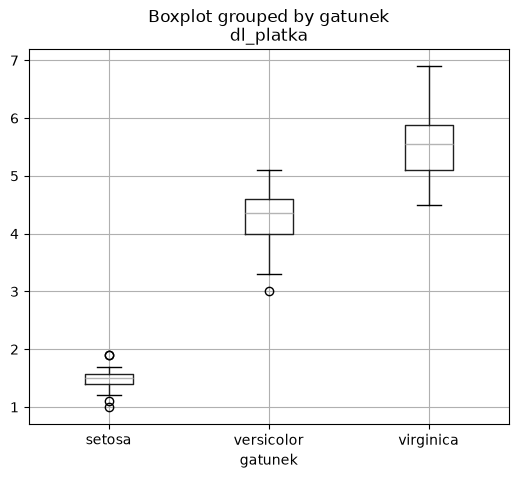

In [28]:
df.boxplot(column='dl_platka', by='gatunek', figsize=(6, 5))

<Axes: title={'center': 'szer_platka'}, xlabel='gatunek'>

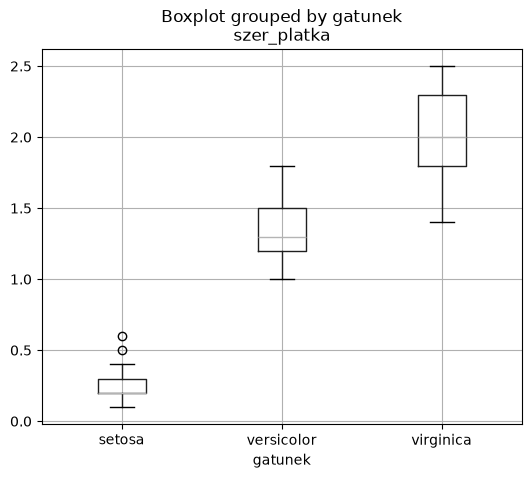

In [29]:
df.boxplot(column='szer_platka', by='gatunek', figsize=(6, 5))

<Axes: title={'center': 'dl_kielicha'}, xlabel='gatunek'>

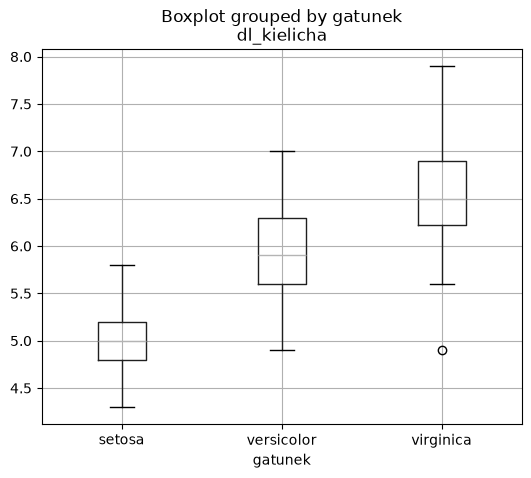

In [30]:
df.boxplot(column='dl_kielicha', by='gatunek', figsize=(6, 5))

<Axes: title={'center': 'szer_kielicha'}, xlabel='gatunek'>

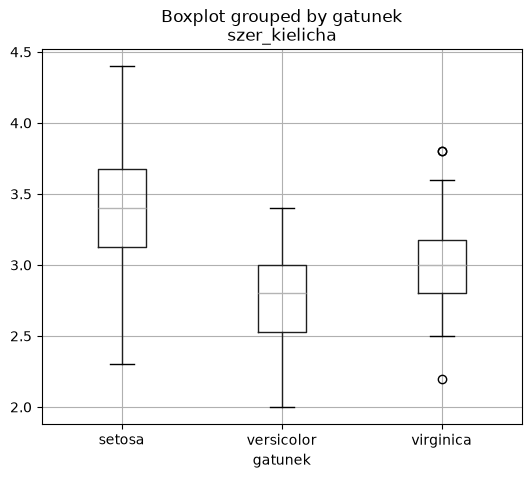

In [31]:
df.boxplot(column='szer_kielicha', by='gatunek', figsize=(6, 5))

**Obserwacje:**
* Przy **długości i szerokości płatka** pudełka trzech gatunków w ogóle na siebie nie nachodzą – to cechy, które najlepiej odróżniają gatunki.
* Przy **długości kielicha** pudełka są przesunięte, ale wąsy mocno się pokrywają.
* **Szerokość kielicha** najsłabiej odróżnia gatunki – pudełka *versicolor* i *virginica* prawie się pokrywają.

## 6. Relacje między kolumnami

In [32]:
df[['dl_kielicha', 'szer_kielicha', 'dl_platka', 'szer_platka']].corr()

,dl_kielicha,szer_kielicha,dl_platka,szer_platka
dl_kielicha,1.000000,-0.109369,0.871754,0.817954
szer_kielicha,-0.109369,1.000000,-0.420516,-0.356544
dl_platka,0.871754,-0.420516,1.000000,0.962757
szer_platka,0.817954,-0.356544,0.962757,1.000000


**Obserwacje:**
* **Długość i szerokość płatka** są bardzo silnie powiązane (0,96) – dłuższy płatek prawie zawsze jest też szerszy.
* **Długość kielicha** jest silnie powiązana z wymiarami płatka (0,82–0,87) – większe kwiaty są większe „we wszystkim”.
* **Szerokość kielicha** ma słabą i ujemną korelację z resztą, np. z długością kielicha -0,11. To dziwne – wychodziłoby, że szerszy kielich jest krótszy. Sprawdzam to na wykresach.

<Axes: title={'center': 'Płatek: długość i szerokość'}, xlabel='dl_platka', ylabel='szer_platka'>

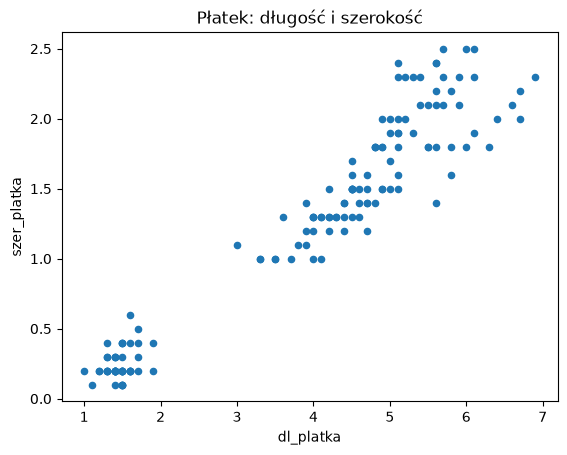

In [33]:
df.plot(kind='scatter', x='dl_platka', y='szer_platka', title='Płatek: długość i szerokość')

<Axes: title={'center': 'Kielich: długość i szerokość'}, xlabel='dl_kielicha', ylabel='szer_kielicha'>

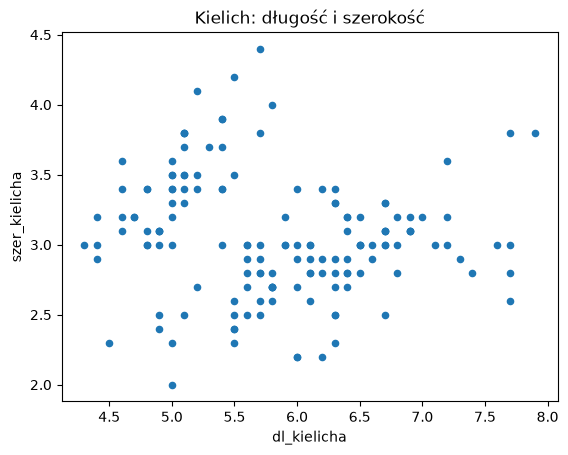

In [34]:
df.plot(kind='scatter', x='dl_kielicha', y='szer_kielicha', title='Kielich: długość i szerokość')

Na wspólnym wykresie nie widać gatunków, więc nakładam trzy wykresy w różnych kolorach.

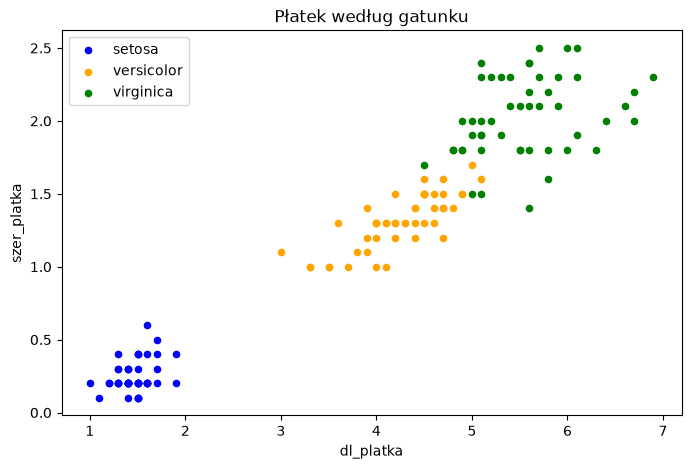

In [35]:
ax = setosa.plot(kind='scatter', x='dl_platka', y='szer_platka', color='blue', figsize=(8, 5), title='Płatek według gatunku')
versicolor.plot(kind='scatter', x='dl_platka', y='szer_platka', color='orange', ax=ax)
virginica.plot(kind='scatter', x='dl_platka', y='szer_platka', color='green', ax=ax)
ax.legend(['setosa', 'versicolor', 'virginica'])

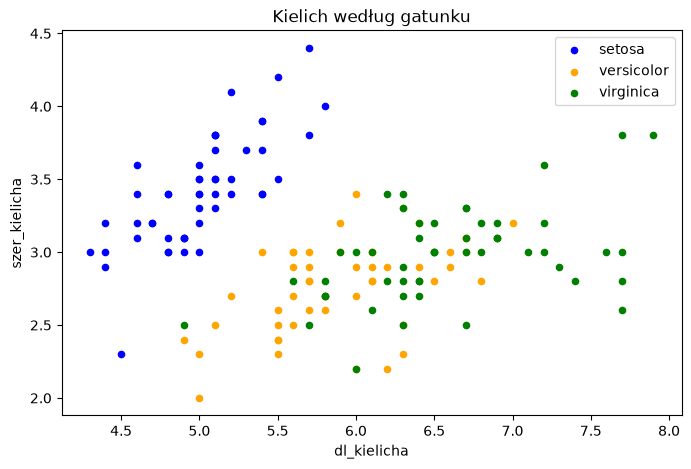

In [36]:
ax = setosa.plot(kind='scatter', x='dl_kielicha', y='szer_kielicha', color='blue', figsize=(8, 5), title='Kielich według gatunku')
versicolor.plot(kind='scatter', x='dl_kielicha', y='szer_kielicha', color='orange', ax=ax)
virginica.plot(kind='scatter', x='dl_kielicha', y='szer_kielicha', color='green', ax=ax)
ax.legend(['setosa', 'versicolor', 'virginica'])

**Obserwacje:**
* **Płatki:** widać trzy wyraźne grupy. *Setosa* jest całkowicie oddzielona w lewym dolnym rogu. *Versicolor* i *virginica* stykają się tylko w małym obszarze.
* **Kielich:** *setosa* tworzy osobną grupę (krótszy, ale szerszy kielich). *Versicolor* i *virginica* mocno się mieszają.
* W każdym gatunku osobno punkty układają się „w górę” – dłuższy kielich jest też szerszy. To przeczy ujemnej korelacji z tabeli. Sprawdzam korelację dla każdego gatunku osobno.

In [37]:
setosa[['dl_kielicha', 'szer_kielicha']].corr()

,dl_kielicha,szer_kielicha
dl_kielicha,1.00000,0.74678
szer_kielicha,0.74678,1.00000


In [38]:
versicolor[['dl_kielicha', 'szer_kielicha']].corr()

,dl_kielicha,szer_kielicha
dl_kielicha,1.000000,0.525911
szer_kielicha,0.525911,1.000000


In [39]:
virginica[['dl_kielicha', 'szer_kielicha']].corr()

,dl_kielicha,szer_kielicha
dl_kielicha,1.000000,0.457228
szer_kielicha,0.457228,1.000000


**Wniosek:**
* W każdym gatunku osobno korelacja długości i szerokości kielicha jest **dodatnia** (od 0,46 do 0,75).
* Dla wszystkich kwiatów razem wychodzi **lekko ujemna** (-0,11).

Dzieje się tak, bo *setosa* ma krótkie, ale szerokie kielichy, a pozostałe gatunki – długie i węższe. Po połączeniu wszystkich gatunków zależność się odwraca.
Nauczka: korelacji policzonej na całym zbiorze nie można interpretować bez sprawdzenia, czy w danych nie ma różnych grup.

## 7. Wartości odstające

<Axes: >

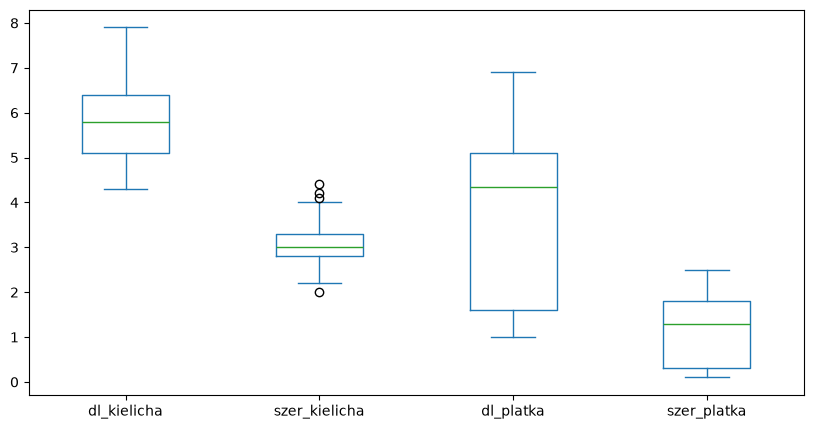

In [40]:
df[['dl_kielicha', 'szer_kielicha', 'dl_platka', 'szer_platka']].plot(kind='box', figsize=(10, 5))

**Obserwacja:** punkty poza wąsami widać tylko przy szerokości kielicha. Wyznaczam granice tak samo jak wąsy wykresu pudełkowego: 1,5 × rozstęp między I a III kwartylem, licząc od kwartyli.

In [41]:
q1 = df['szer_kielicha'].describe()['25%']
q3 = df['szer_kielicha'].describe()['75%']
roznica = q3 - q1

dolna_granica = q1 - 1.5 * roznica
gorna_granica = q3 + 1.5 * roznica
print('Dolna granica:', dolna_granica)
print('Górna granica:', gorna_granica)

Dolna granica: 2.05
Górna granica: 4.05


In [42]:
df[(df['szer_kielicha'] < dolna_granica) | (df['szer_kielicha'] > gorna_granica)]

,dl_kielicha,szer_kielicha,dl_platka,szer_platka,gatunek,pole_platka
15,5.7,4.4,1.5,0.4,setosa,0.60
32,5.2,4.1,1.5,0.1,setosa,0.15
33,5.5,4.2,1.4,0.2,setosa,0.28
60,5.0,2.0,3.5,1.0,versicolor,3.50


**Obserwacje:**
* Odstające są 4 kwiaty: trzy *setosa* z bardzo szerokim kielichem (4,1–4,4 cm) i jedna *versicolor* z bardzo wąskim (2,0 cm).
* To nie są błędy. *Setosa* ma najszersze kielichy ze wszystkich gatunków (punkt 5), więc wysokie wartości są u niej naturalne. 2,0 cm u *versicolor* jest blisko minimum innych gatunków (2,2–2,3 cm).
* Wykresy pudełkowe dla gatunków (punkt 5.1) pokazują jeszcze kilka pojedynczych punktów, ale wszystkie mieszczą się w zakresach spotykanych u innych kwiatów.

**Decyzja:** nie usuwam wartości odstających. To naturalne różnice między kwiatami, a ich usunięcie zafałszowałoby obraz danych.

## 8. Podsumowanie i wnioski końcowe

### Jakość danych
* Zbiór ma 150 kwiatów, po 50 z każdego gatunku, bez braków danych i z poprawnymi typami.
* Są 3 zduplikowane wiersze. Przy pomiarach z dokładnością do 0,1 cm takie powtórzenia są możliwe, a ich usunięcie nie zmienia wyników – zostawiłem je.
* Wartości odstające (4 kwiaty, szerokość kielicha) są naturalne dla danych – zostawiłem je.
* Dane nie wymagały naprawy ani uzupełniania.

### Najważniejsze wnioski
1. **Wymiary płatka najlepiej odróżniają gatunki.** Pudełka trzech gatunków nie nachodzą na siebie, a na wykresie punktowym tworzą trzy wyraźne grupy.
2. ***Setosa* wyraźnie różni się od pozostałych** – płatki ma krótsze niż 2 cm i węższe niż 0,7 cm. Jednocześnie ma najszerszy kielich.
3. ***Versicolor* i *virginica* są do siebie podobne** – różnią się głównie wielkością (*virginica* jest większa), a ich zakresy częściowo się nakładają.
4. **Pole płatka** (nowa kolumna) prawie samo rozdziela gatunki.
5. **Szerokość kielicha** najsłabiej odróżnia gatunki.
6. **Korelacja na całym zbiorze może wprowadzać w błąd** – dla kielicha wyszła lekko ujemna, a w każdym gatunku osobno jest dodatnia.

### Czego się nauczyłem przy tej analizie
* Nie oceniać danych tylko po `head()` – mogą być posortowane.
* Duplikat albo wartość odstająca to sygnał do sprawdzenia, a nie automatyczny powód do usunięcia wiersza.
* Wyniki dla całego zbioru warto zawsze porównać z wynikami w grupach.